# 11. QoS results per metric, scenario and class

Plots of the sweep summary: every metric of notebook 10, per traffic class and scenario, against
distance, density and CBR. Error bars are 95 % confidence intervals over the seeds (each seed is
another SUMO trace). The sweep shown is `results/qos/$QOS_SWEEP` (default `qos_full`, falls back to
the smoke sweep).

Unless a figure says otherwise it shows the **baseline** condition, the `reeval_preempt`
policy (the full Mode 2 feature set) and, for `highway_cpm`, the `sps_max` variant; notebook 12
compares the policies and section 8 the CPM variants.

In [1]:
import os, sys, json, subprocess
sys.path.insert(0, os.path.abspath("../../tools"))
sys.path.insert(0, os.path.abspath("../../tools/qos"))
import morev2x_results as mr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

mr.apply_chart_style()
os.chdir(mr.ROOT)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)

import plots
s = plots.Sweep()
print(s.note())
flows, by_distance, causes = s.flows, s.by_distance, s.causes
POLICY = "reeval_preempt" if "reeval_preempt" in set(flows.policy) else flows.policy.iloc[0]
# One variant per scenario outside section 8: SPS reserving for the largest CPM in highway_cpm
REFERENCE = {sc: ("sps_max" if "sps_max" in set(g.variant) else sorted(g.variant.unique())[0])
             for sc, g in flows.groupby("scenario")}
def reference(frame):
    return frame[frame.variant == frame.scenario.map(REFERENCE)]
flows_ref, by_distance_ref, causes_ref = reference(flows), reference(by_distance), reference(causes)
base = flows_ref[(flows_ref.condition == "baseline") & (flows_ref.policy == POLICY)]

Sweep qos_smoke: 18 runs, 1 seed(s). SMOKE DATA: 4 s runs on short roads, one seed. The figures show that the pipeline works, not the results. Set QOS_SWEEP=qos_full once the full sweep is downloaded.


## 1. PDR and QoS-PDR against distance

PDR counts any decoded copy, QoS-PDR only the ones within the PDB of the class. The gap
between the two curves is the share of packets that arrived but too late.

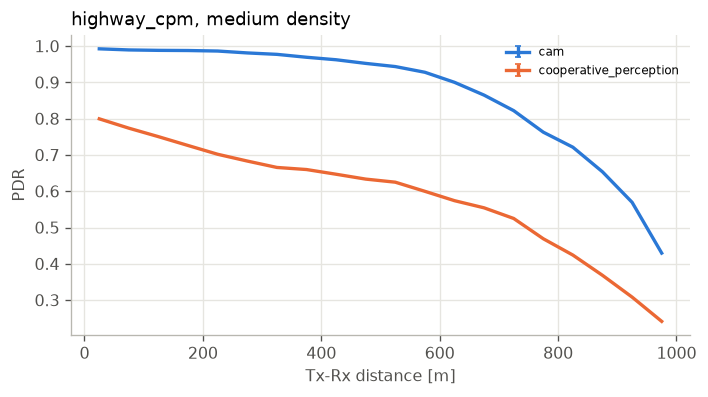

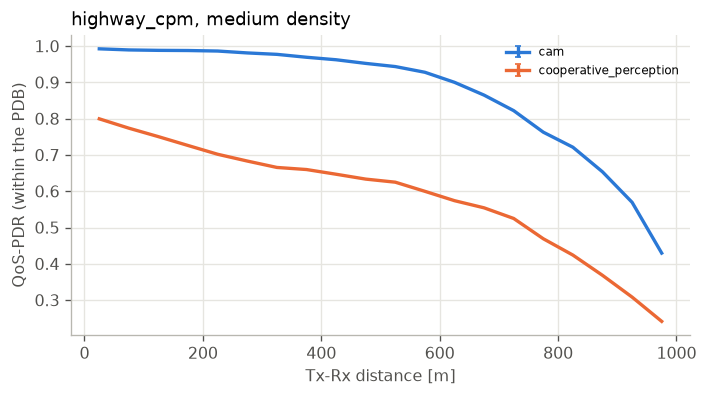

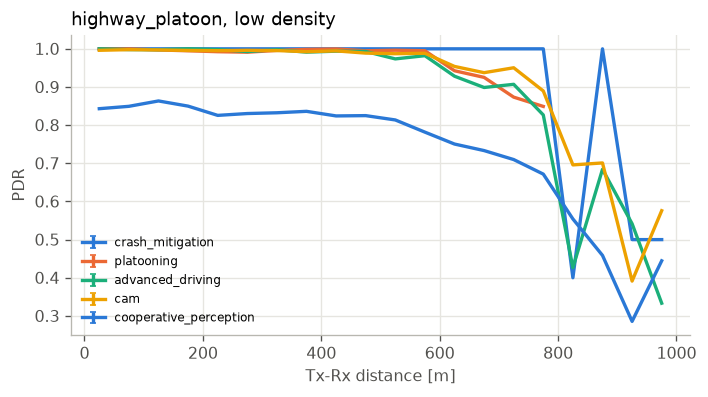

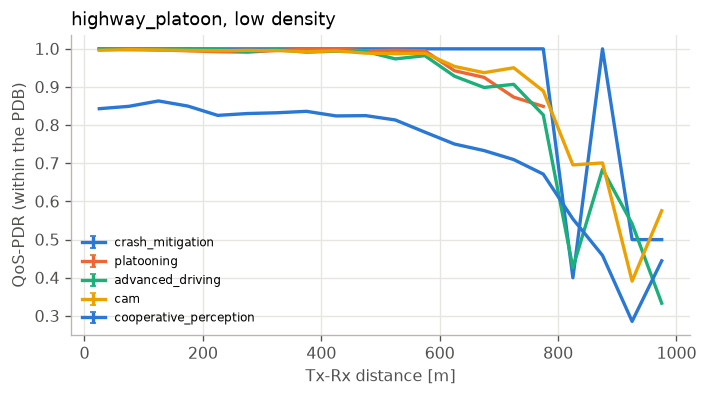

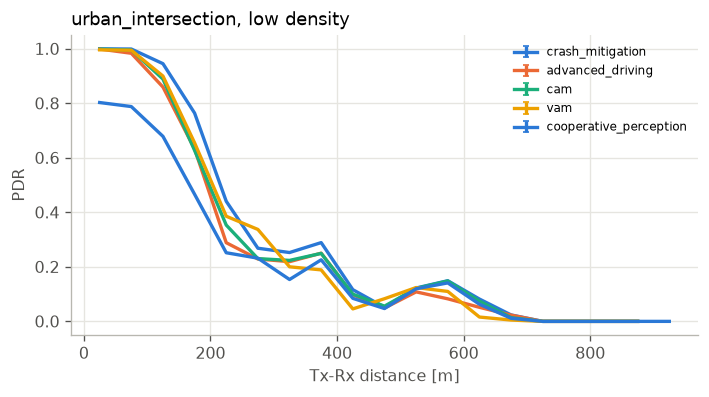

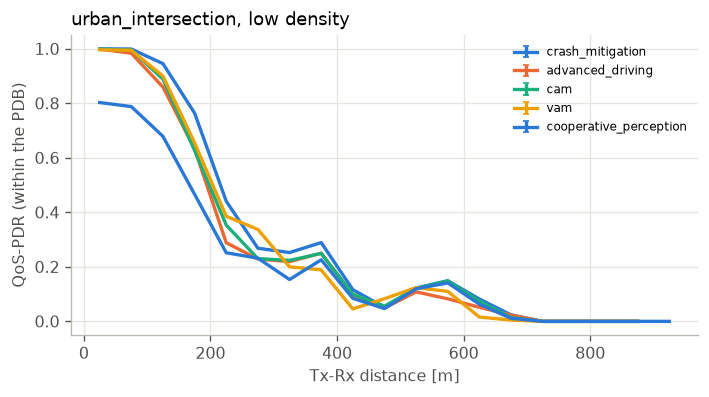

In [2]:
def distance_plot(scenario, value, ylabel, density=None, policy=POLICY, condition="baseline", variant=None):
    frame = by_distance[(by_distance.scenario == scenario) & (by_distance.policy == policy) & (by_distance.condition == condition)]
    frame = frame[frame.variant == (variant or REFERENCE[scenario])]
    densities = sorted(frame.density.unique()) if density is None else [density]
    fig, axes = plt.subplots(1, len(densities), figsize=(6 * len(densities), 3.4), sharey=True, squeeze=False)
    for ax, d in zip(axes[0], densities):
        part = frame[frame.density == d]
        for name in plots.order_classes(part.name.unique()):
            stats = plots.mean_ci(part[part.name == name], value, "bin")
            ax.errorbar(stats["bin"] + 25, stats["mean"], yerr=stats["ci"], label=name, capsize=2)
        ax.set_title("%s, %s density" % (scenario, d)); ax.set_xlabel("Tx-Rx distance [m]")
    axes[0][0].set_ylabel(ylabel); axes[0][-1].legend(fontsize=7)
    plt.tight_layout()

for scenario in sorted(base.scenario.unique()):
    distance_plot(scenario, "pdr", "PDR")
    distance_plot(scenario, "qos_pdr", "QoS-PDR (within the PDB)")

## 2. Measured PER against the PQI target

1 − QoS-PDR within 300 m, per class, against the PER of its PQI (dashed). A bar under the dash meets
the target. With no retransmissions the 10⁻⁴ and 10⁻⁵ targets are not reachable, the figure shows by
how far, on a log scale.

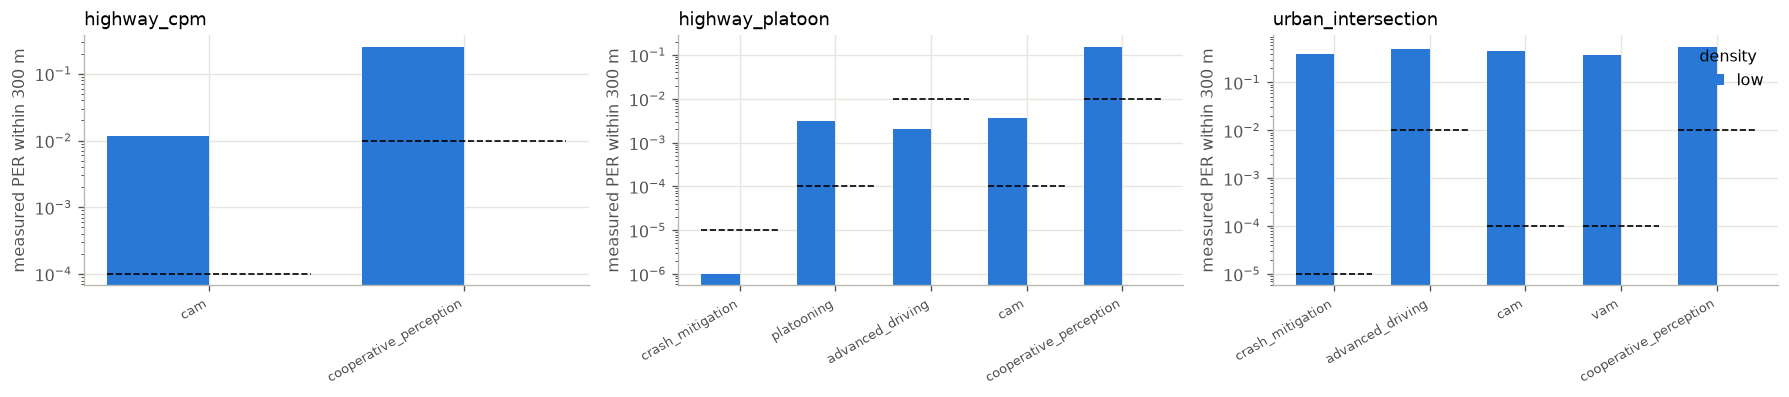

In [3]:
near = by_distance_ref[(by_distance_ref.bin < 300) & (by_distance_ref.condition == "baseline") & (by_distance_ref.policy == POLICY)].copy()
near["failed"] = (1 - near.qos_pdr) * near.attempts
per = near.groupby(["scenario", "density", "seed", "name"])[["failed", "attempts"]].sum().reset_index()
per["per"] = per.failed / per.attempts
targets = flows.drop_duplicates("name").set_index("name").per_target
scenarios = sorted(per.scenario.unique())
fig, axes = plt.subplots(1, len(scenarios), figsize=(5 * len(scenarios), 3.4), squeeze=False)
for ax, scenario in zip(axes[0], scenarios):
    part = per[per.scenario == scenario]
    names = plots.order_classes(part.name.unique())
    for k, d in enumerate(sorted(part.density.unique())):
        stats = plots.mean_ci(part[part.density == d], "per", "name").set_index("name").reindex(names)
        ax.bar(np.arange(len(names)) + 0.4 * k - 0.2, stats["mean"].clip(lower=1e-6), 0.4, yerr=stats["ci"], label=d)
    for i, name in enumerate(names):
        ax.hlines(targets[name], i - 0.4, i + 0.4, colors="black", linestyles="--", lw=1)
    ax.set_yscale("log"); ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=30, ha="right", fontsize=8)
    ax.set_title(scenario); ax.set_ylabel("measured PER within 300 m")
axes[0][-1].legend(title="density")
plt.tight_layout()

## 3. PIR, disconnection time and age of information

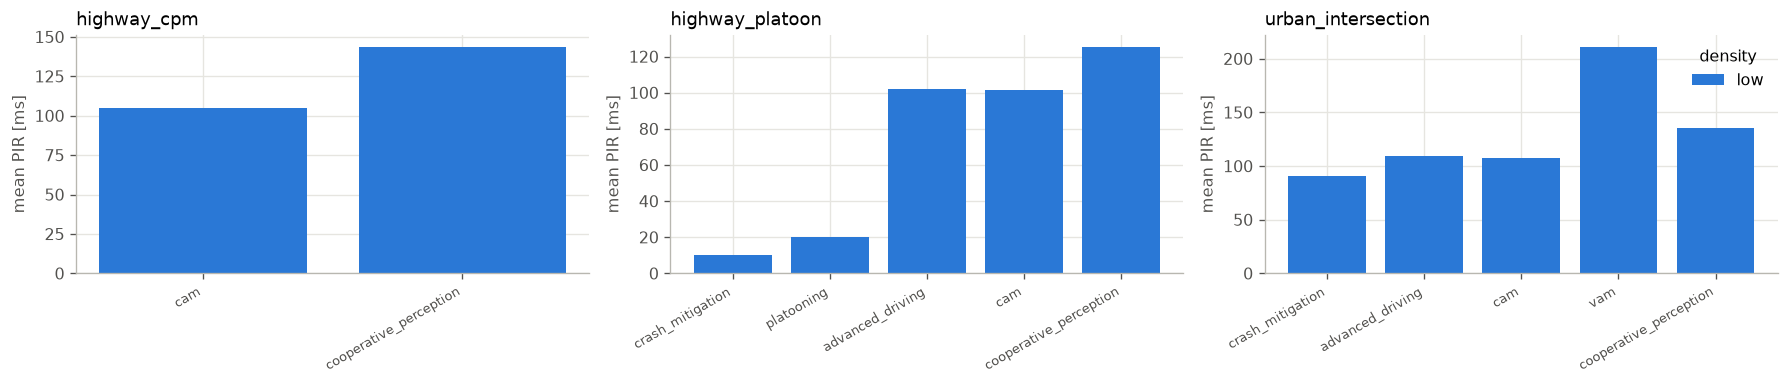

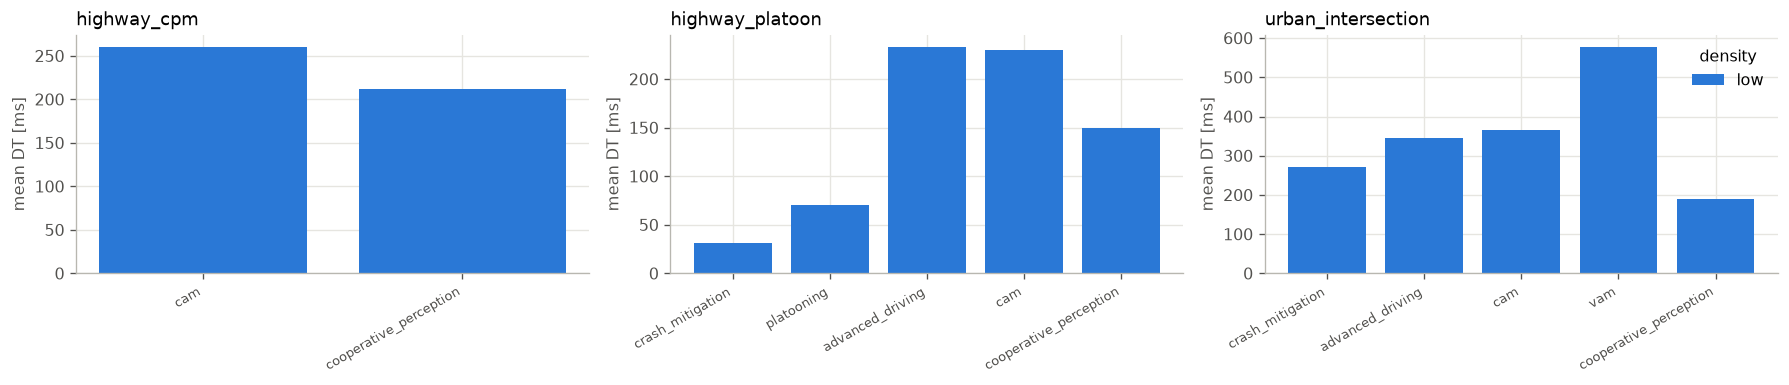

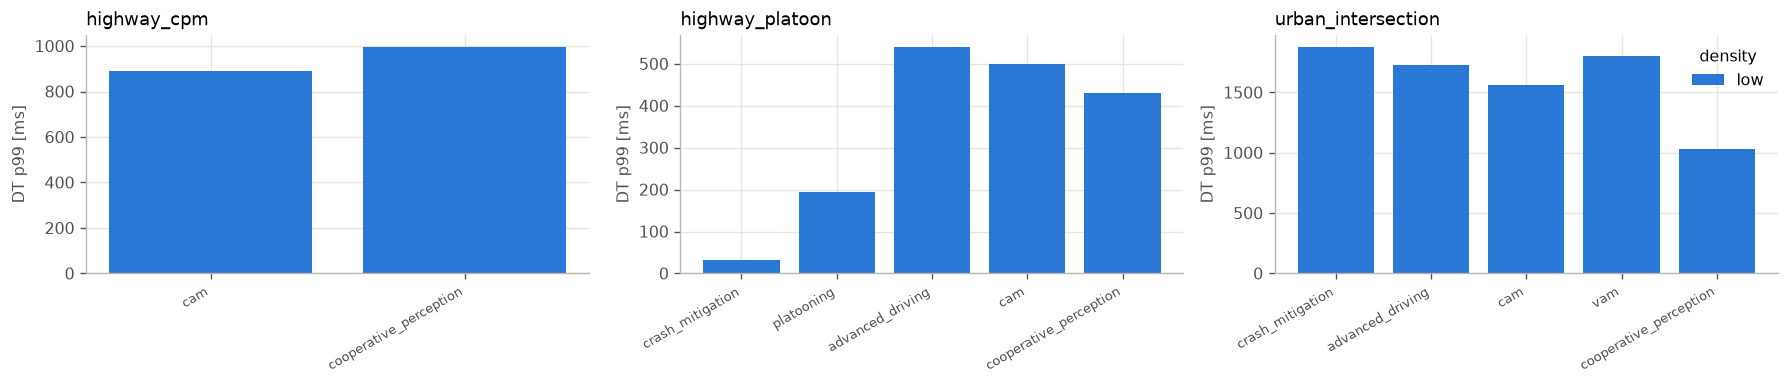

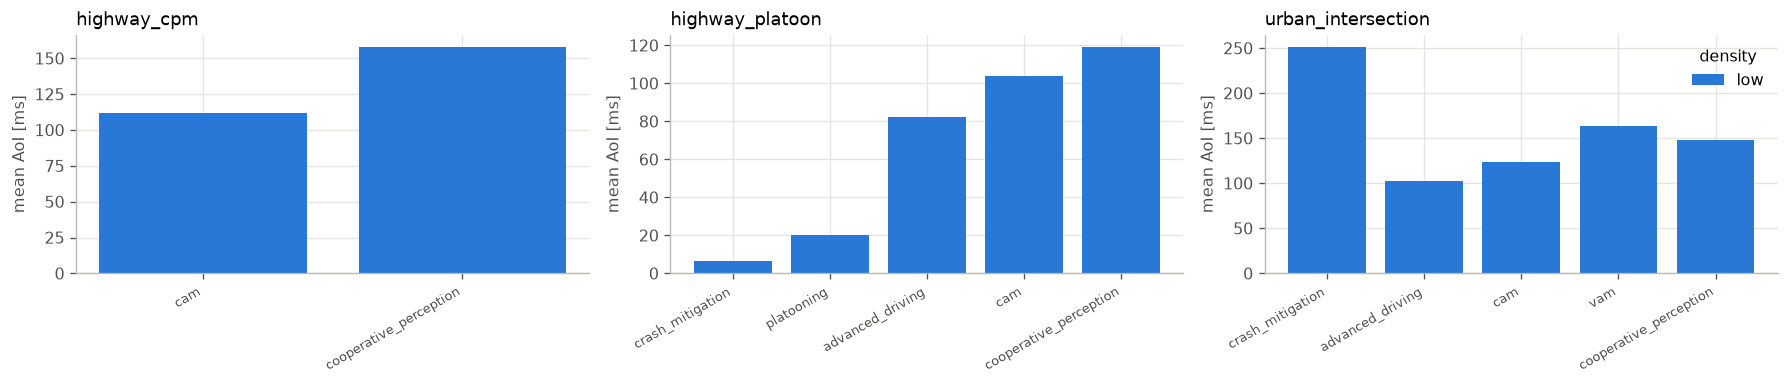

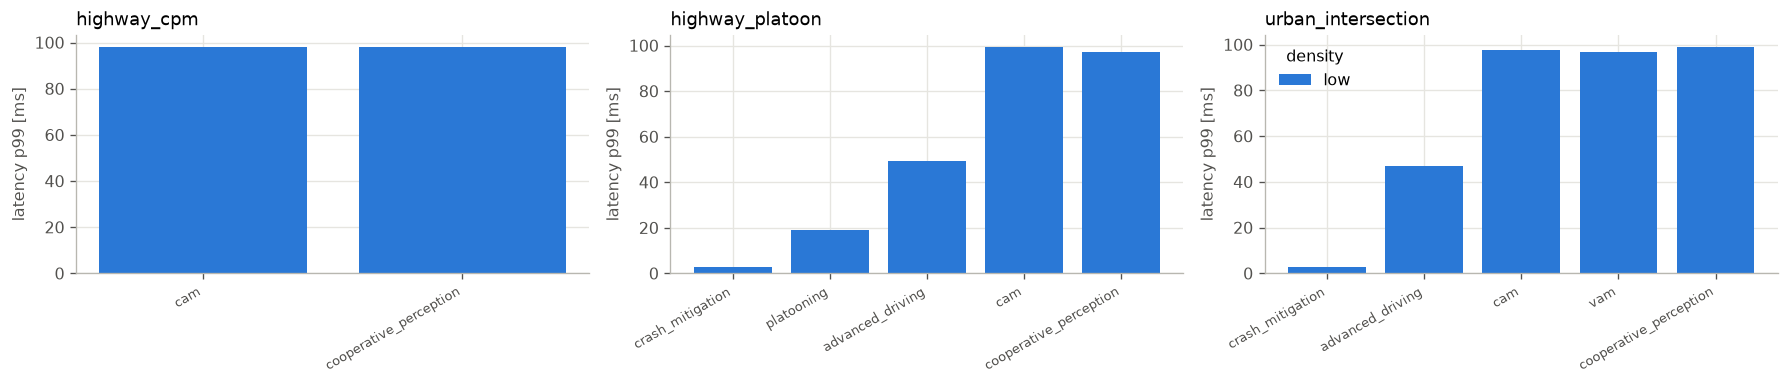

In [4]:
def class_bars(value, ylabel, frame=base, log=False):
    scenarios = sorted(frame.scenario.unique())
    fig, axes = plt.subplots(1, len(scenarios), figsize=(5 * len(scenarios), 3.3), squeeze=False)
    for ax, scenario in zip(axes[0], scenarios):
        part = frame[frame.scenario == scenario]
        names = plots.order_classes(part.name.unique())
        densities = sorted(part.density.unique())
        width = 0.8 / max(len(densities), 1)
        for k, d in enumerate(densities):
            stats = plots.mean_ci(part[part.density == d], value, "name").set_index("name").reindex(names)
            ax.bar(np.arange(len(names)) + width * (k - (len(densities) - 1) / 2), stats["mean"], width, yerr=stats["ci"], label=d)
        ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=30, ha="right", fontsize=8)
        ax.set_title(scenario); ax.set_ylabel(ylabel)
        if log:
            ax.set_yscale("log")
    axes[0][-1].legend(title="density")
    plt.tight_layout()

class_bars("pir_mean_ms", "mean PIR [ms]")
class_bars("dt_mean_ms", "mean DT [ms]")
class_bars("dt_p99_ms", "DT p99 [ms]")
class_bars("aoi_mean_ms", "mean AoI [ms]")
class_bars("latency_p99_ms", "latency p99 [ms]")

Distribution of the disconnection times, all seeds together. DT is the time a receiver
stayed without news **when** it lost something, so its tail is what a safety application sees.

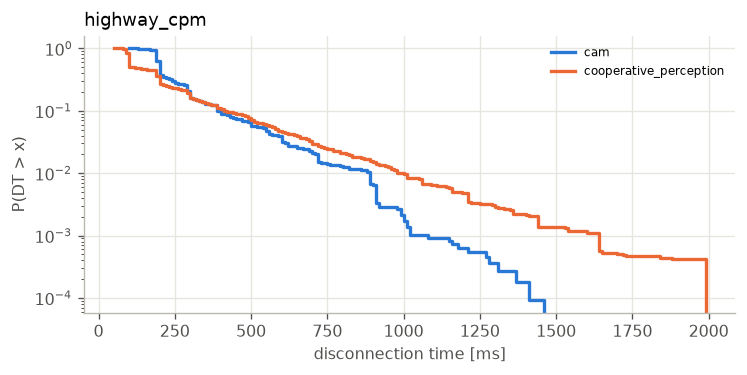

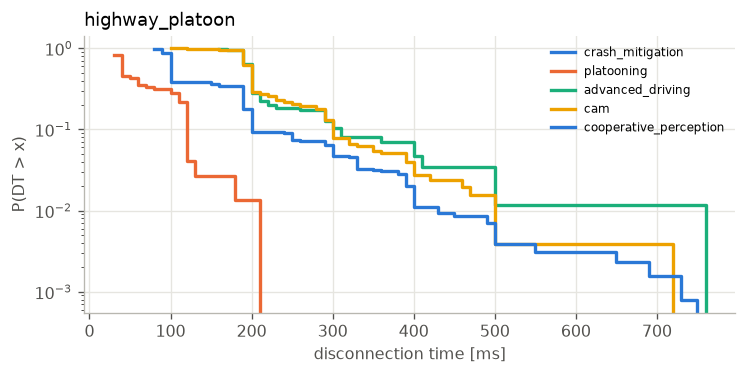

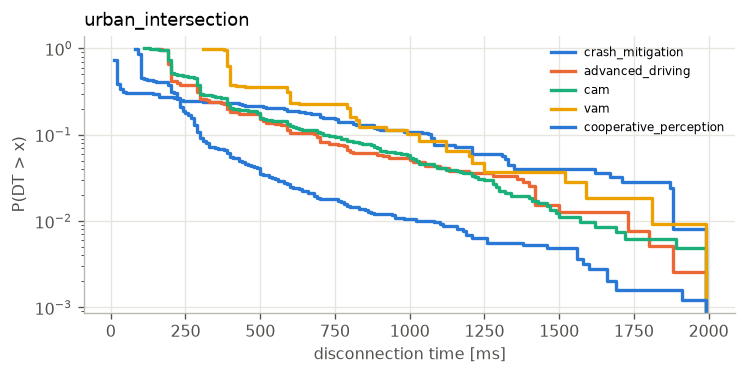

In [5]:
h = reference(s.histograms)
h = h[(h.metric == "dt") & (h.condition == "baseline") & (h.policy == POLICY)]
for scenario in sorted(h.scenario.unique()):
    part = h[h.scenario == scenario]
    plt.figure(figsize=(7, 3))
    for name in plots.order_classes(part.name.unique()):
        g = part[part.name == name].groupby("edge_s")["count"].sum().sort_index()
        survival = 1 - g.cumsum() / g.sum()
        plt.step(1000 * g.index, survival, where="post", label=name)
    plt.yscale("log"); plt.xlabel("disconnection time [ms]"); plt.ylabel("P(DT > x)"); plt.title(scenario); plt.legend(fontsize=7)

## 4. Collisions and the hidden-node metric

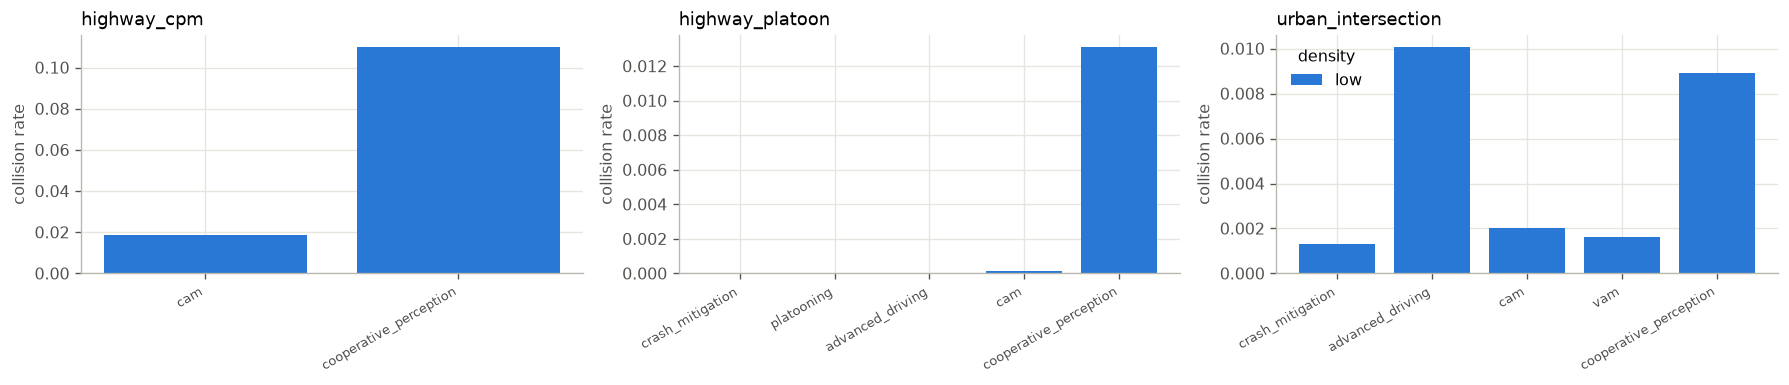

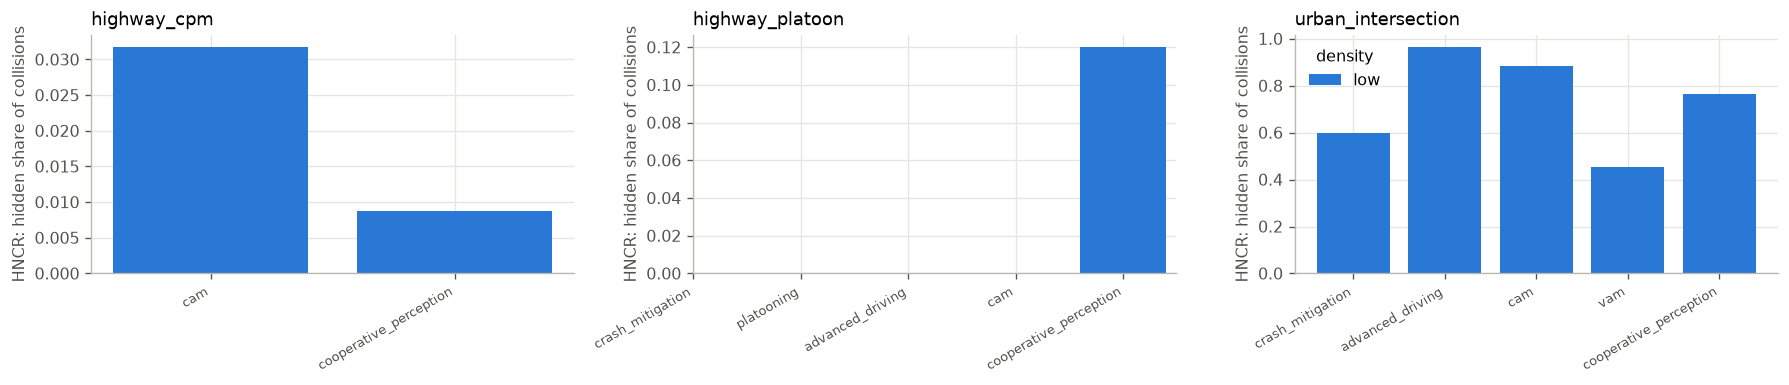

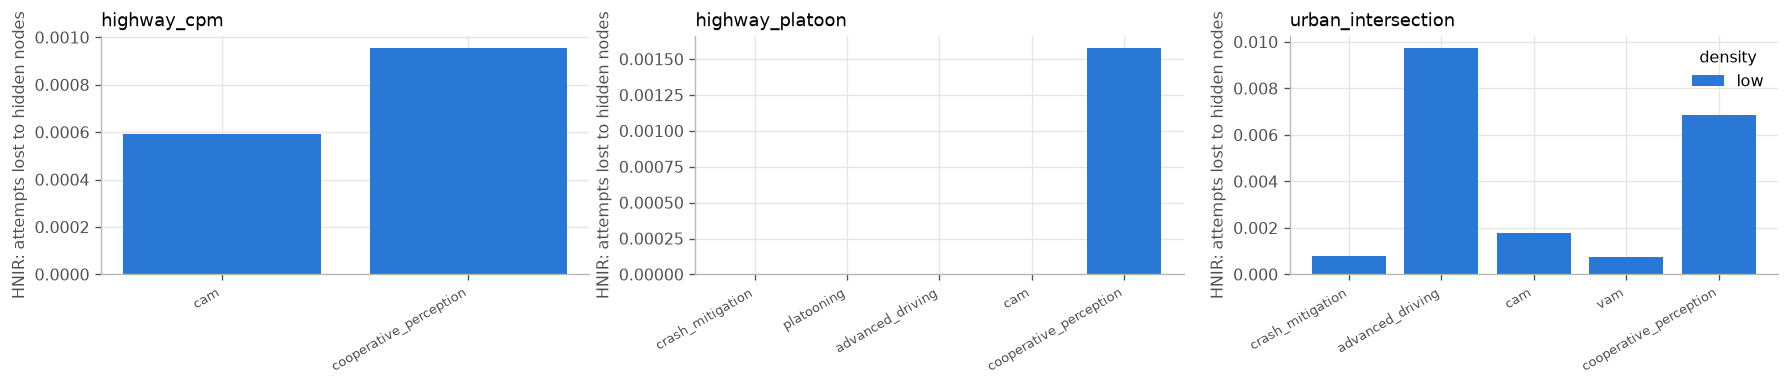

In [6]:
class_bars("collision_rate", "collision rate")
class_bars("hncr", "HNCR: hidden share of collisions")
class_bars("hnir", "HNIR: attempts lost to hidden nodes")

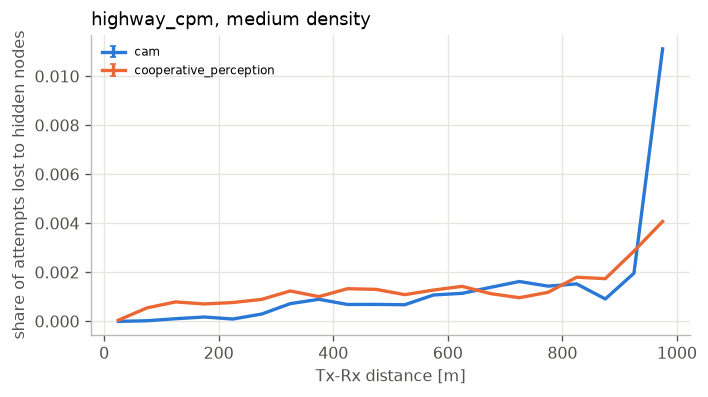

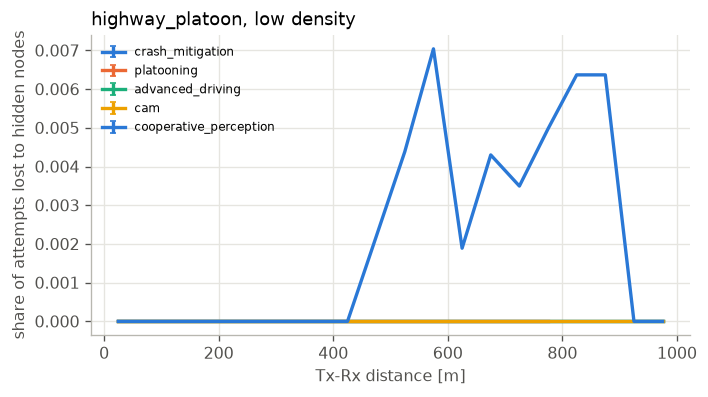

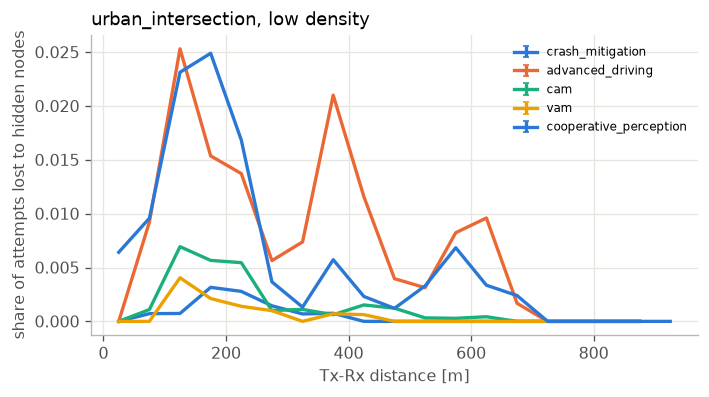

In [7]:
for scenario in sorted(base.scenario.unique()):
    distance_plot(scenario, "hidden", "share of attempts lost to hidden nodes")

## 5. Root causes of the failures

Each failed attempt has one cause (notebook 10, section 7). Shares of all failures per class,
then against distance for the densest case.

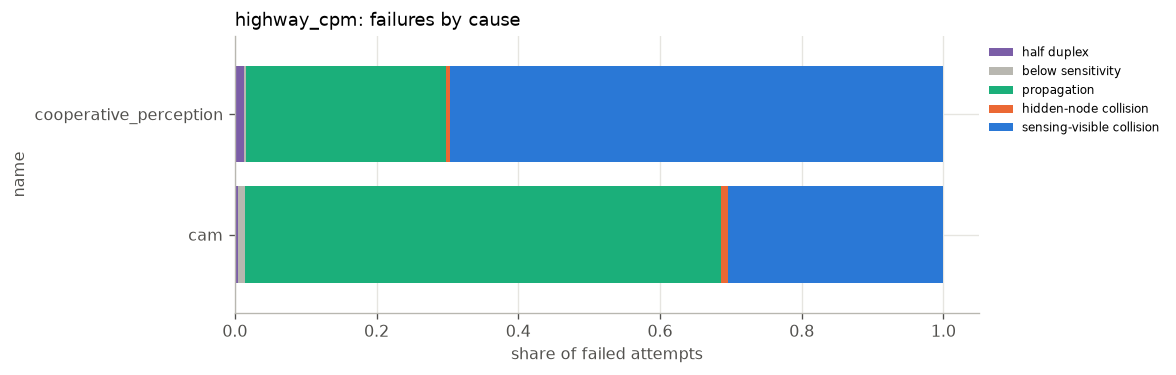

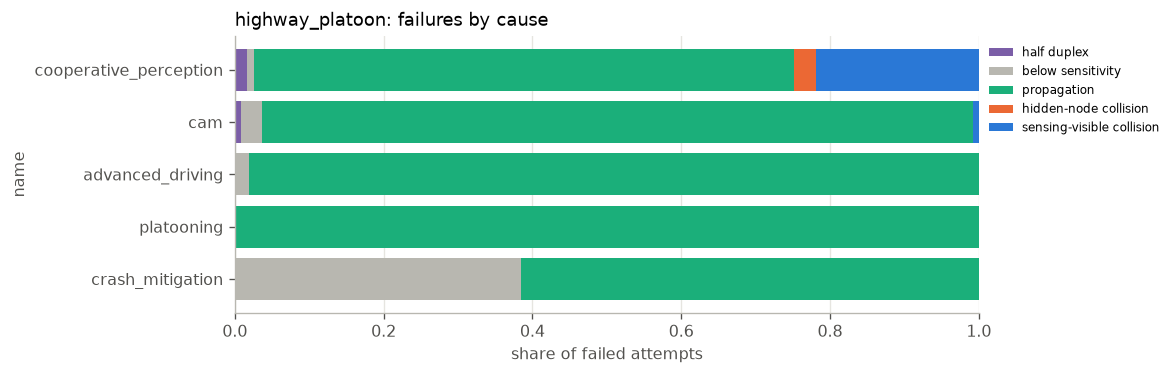

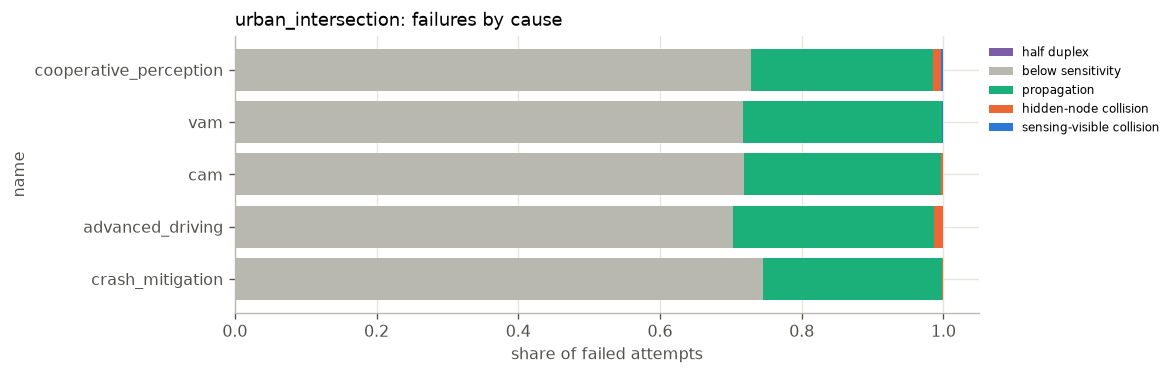

In [8]:
fail = causes_ref[(causes_ref.cause != "decoded in time") & (causes_ref.condition == "baseline") & (causes_ref.policy == POLICY)]
for scenario in sorted(fail.scenario.unique()):
    part = fail[fail.scenario == scenario]
    table = part.groupby(["name", "cause"])["count"].sum().unstack(fill_value=0)
    table = table.reindex(index=plots.order_classes(table.index), columns=[c for c in plots.CAUSE_ORDER if c in table.columns])
    share = table.div(table.sum(axis=1), axis=0)
    share.plot.barh(stacked=True, color=[plots.CAUSE_COLORS[c] for c in share.columns], figsize=(8, 3), width=0.8)
    plt.title(scenario + ": failures by cause"); plt.xlabel("share of failed attempts"); plt.legend(fontsize=7, bbox_to_anchor=(1, 1))

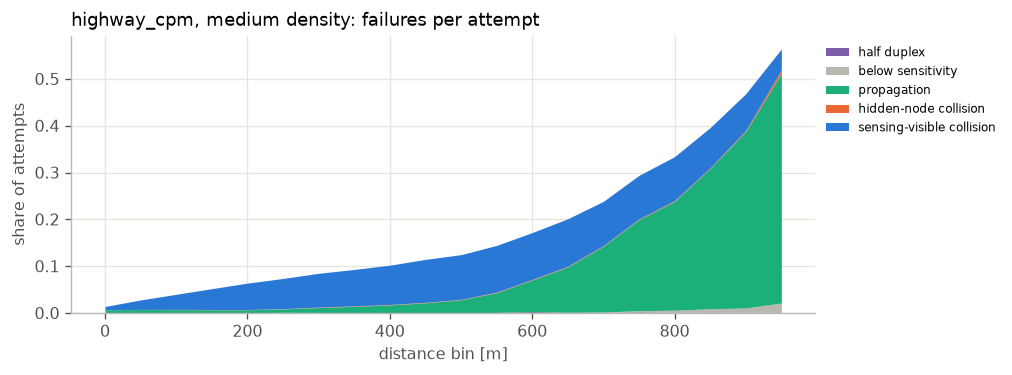

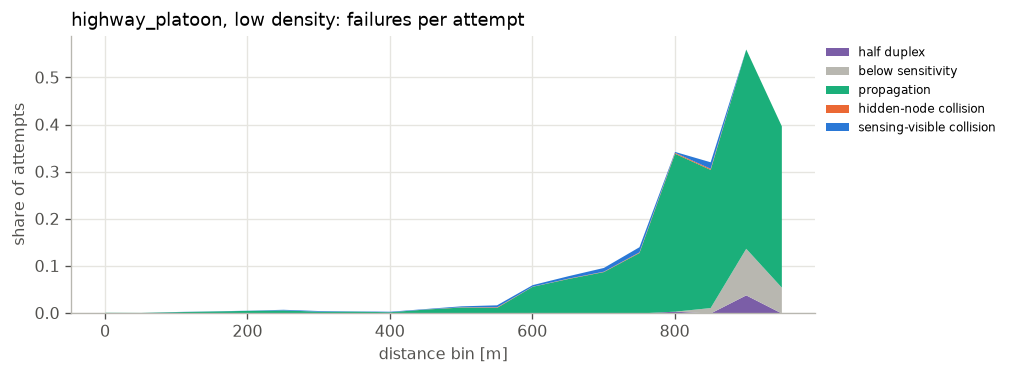

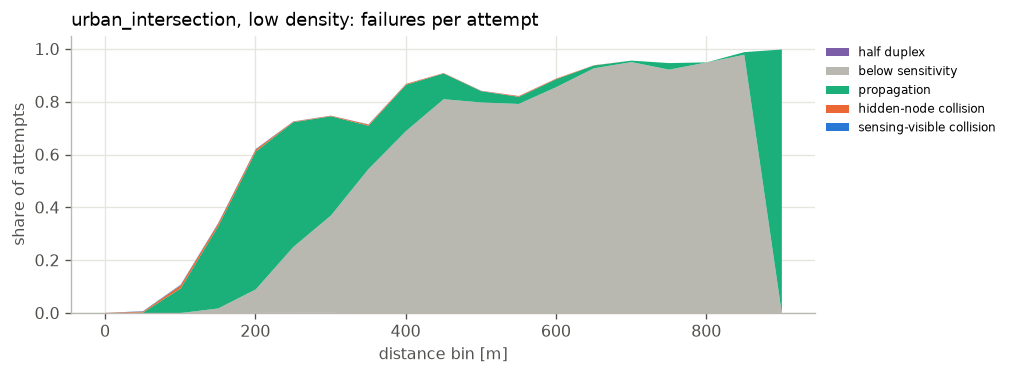

In [9]:
for scenario in sorted(fail.scenario.unique()):
    part = fail[(fail.scenario == scenario) & (fail.density == sorted(fail[fail.scenario == scenario].density.unique())[-1])]
    table = part.groupby(["bin", "cause"])["count"].sum().unstack(fill_value=0)
    table = table[[c for c in plots.CAUSE_ORDER if c in table.columns]]
    total = by_distance_ref[(by_distance_ref.scenario == scenario) & (by_distance_ref.condition == "baseline") & (by_distance_ref.policy == POLICY)]
    attempts = total[total.density == part.density.iloc[0]].groupby("bin").attempts.sum()
    (table.div(attempts, axis=0)).plot.area(color=[plots.CAUSE_COLORS[c] for c in table.columns], figsize=(8, 3), lw=0)
    plt.title("%s, %s density: failures per attempt" % (scenario, part.density.iloc[0])); plt.xlabel("distance bin [m]")
    plt.ylabel("share of attempts"); plt.legend(fontsize=7, bbox_to_anchor=(1, 1))

## 6. Channel load: CBR, occupancy, and the metrics against CBR

In [10]:
cbr = flows_ref.drop_duplicates("id")
stats = plots.mean_ci(cbr[cbr.condition == "baseline"], "cbr_mean", ["scenario", "density", "policy"])
stats.pivot_table(index=["scenario", "density"], columns="policy", values="mean").round(3)

,policy,off,reeval,reeval_preempt
scenario,density,,,
highway_cpm,medium,NaN,NaN,0.560
highway_platoon,low,0.309,0.304,0.308
urban_intersection,low,0.101,0.100,0.100


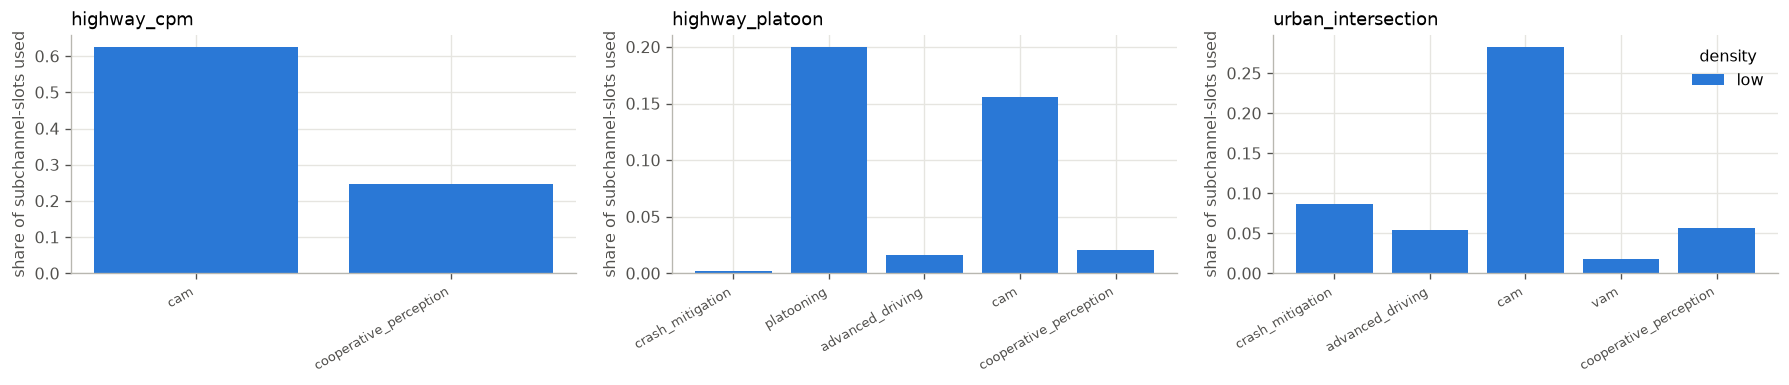

In [11]:
class_bars("occupancy", "share of subchannel-slots used")

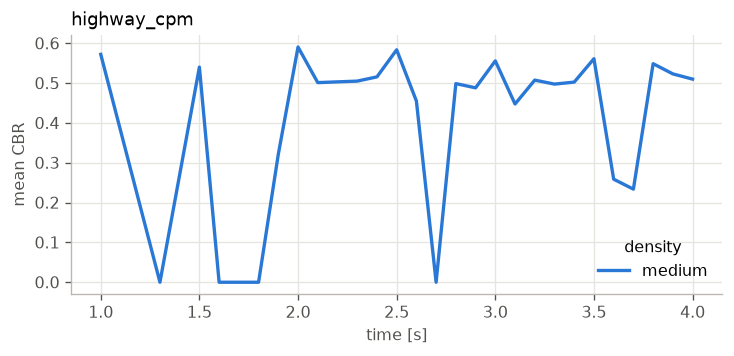

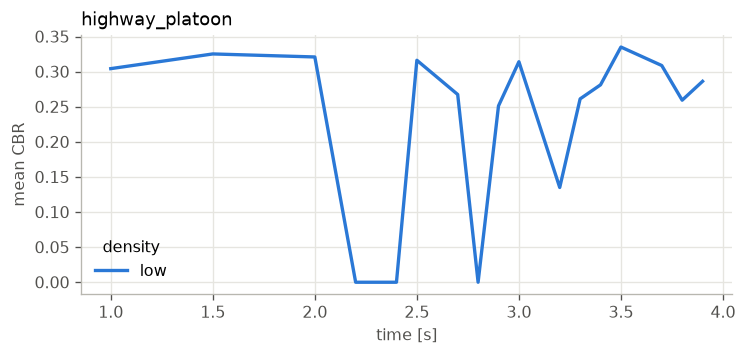

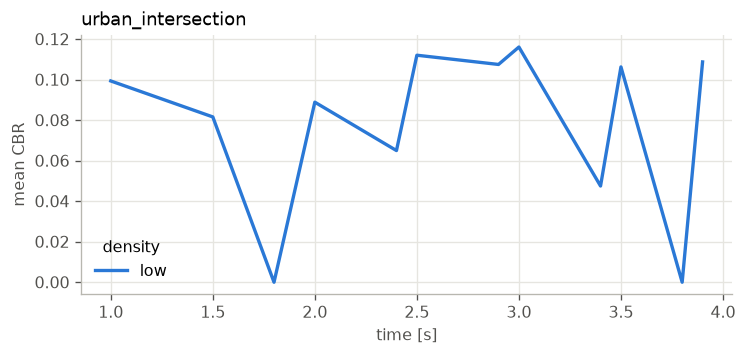

In [12]:
ct = reference(s.cbr_time)
ct = ct[(ct.condition == "baseline") & (ct.policy == POLICY)]
for scenario in sorted(ct.scenario.unique()):
    plt.figure(figsize=(7, 2.8))
    for d, g in ct[ct.scenario == scenario].groupby("density"):
        m = g.groupby("time")["mean"].mean()
        plt.plot(m.index, m.values, label=d)
    plt.xlabel("time [s]"); plt.ylabel("mean CBR"); plt.title(scenario); plt.legend(title="density")

Every run gives one point per class: QoS-PDR within 300 m against the mean CBR of the run.
This puts the scenarios and densities on one load axis.

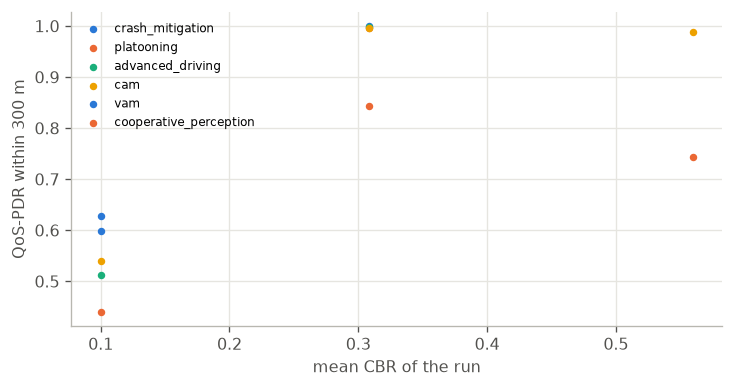

In [13]:
near_pdr = near.groupby(["id", "name"]).apply(lambda g: np.average(g.qos_pdr, weights=g.attempts)).rename("qos_pdr_300").reset_index()
points = near_pdr.merge(flows_ref.drop_duplicates("id")[["id", "scenario", "cbr_mean"]], on="id")
plt.figure(figsize=(7, 3.4))
for name in plots.order_classes(points.name.unique()):
    g = points[points.name == name]
    plt.scatter(g.cbr_mean, g.qos_pdr_300, s=12, label=name)
plt.xlabel("mean CBR of the run"); plt.ylabel("QoS-PDR within 300 m"); plt.legend(fontsize=7)

## 7. Platooning under jamming, loss bursts and stack latency

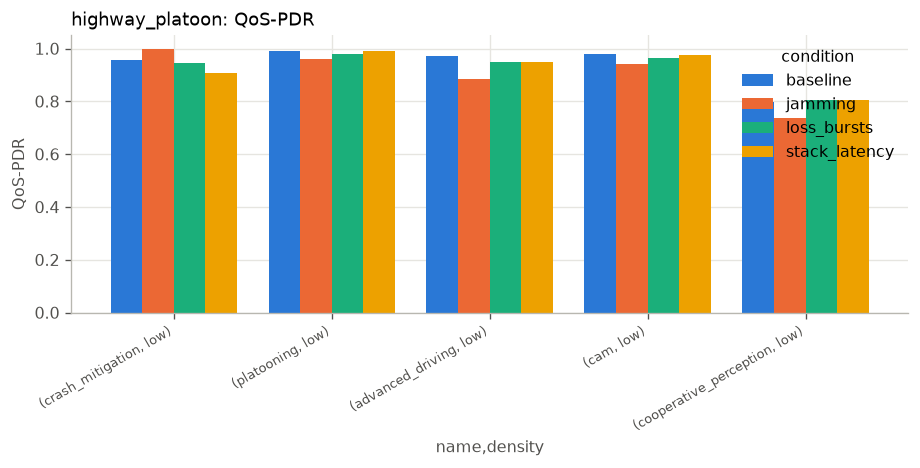

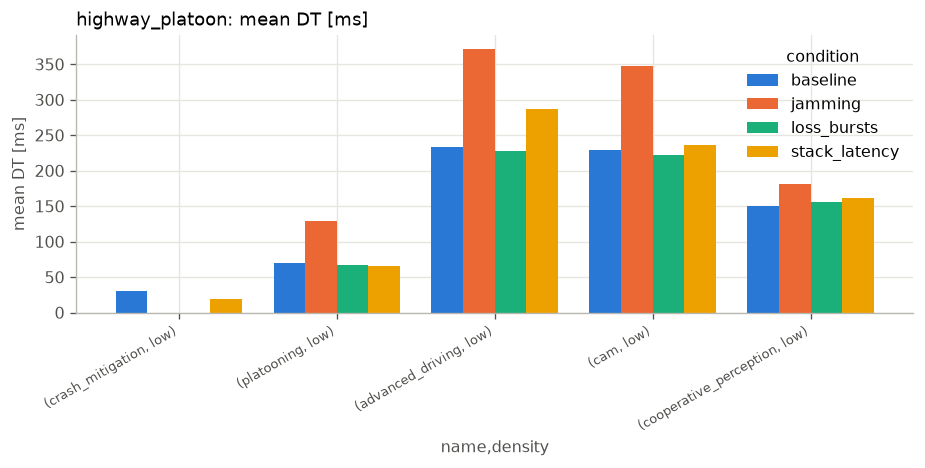

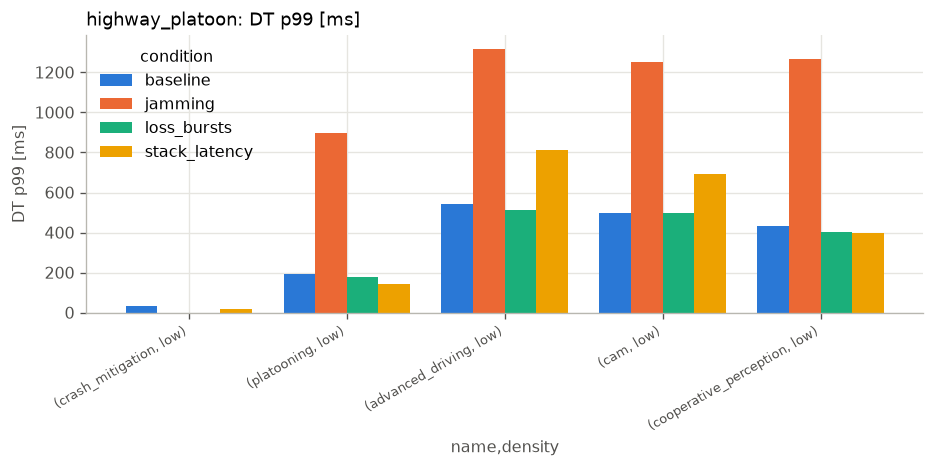

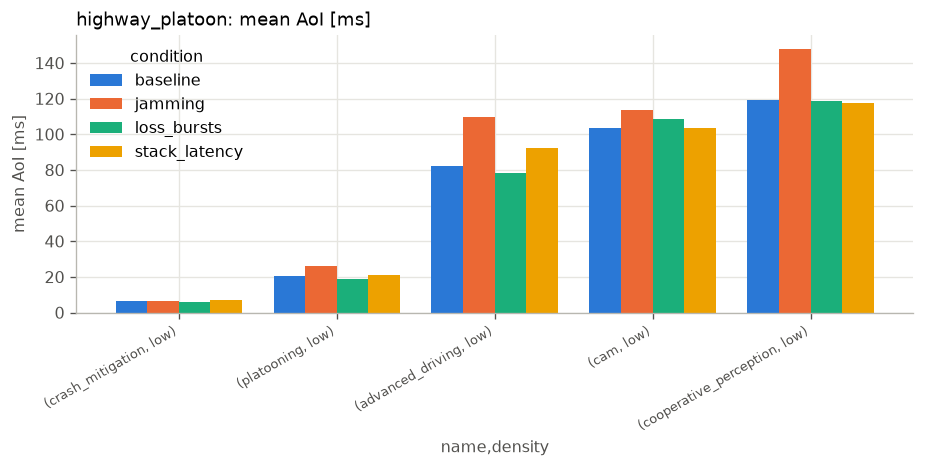

In [14]:
platoon = flows[(flows.scenario == "highway_platoon") & (flows.policy == POLICY)]
if len(platoon):
    for value, label in (("qos_pdr", "QoS-PDR"), ("dt_mean_ms", "mean DT [ms]"), ("dt_p99_ms", "DT p99 [ms]"), ("aoi_mean_ms", "mean AoI [ms]")):
        stats = plots.mean_ci(platoon, value, ["name", "condition", "density"])
        table = stats.pivot_table(index=["name", "density"], columns="condition", values="mean")
        conditions = [c for c in ["baseline", "jamming", "loss_bursts", "stack_latency"] if c in table.columns]
        table = table[conditions].reindex(plots.order_classes(table.index.get_level_values(0).unique()), level=0)
        table.plot.bar(figsize=(9, 3), width=0.8); plt.ylabel(label); plt.title("highway_platoon: " + label)
        plt.xticks(rotation=30, ha="right", fontsize=8)

## 8. CPM contention: SPS against aggressive reselection

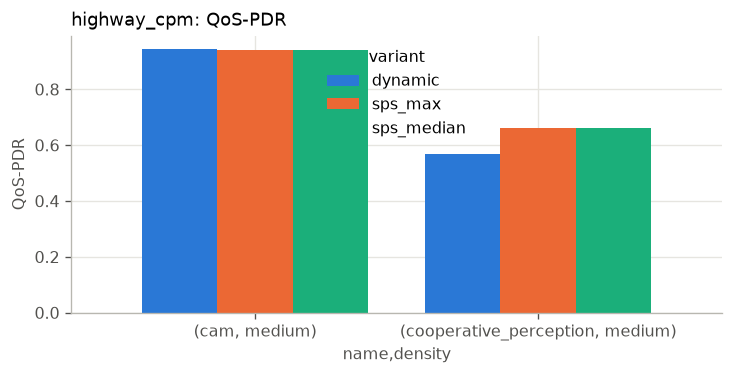

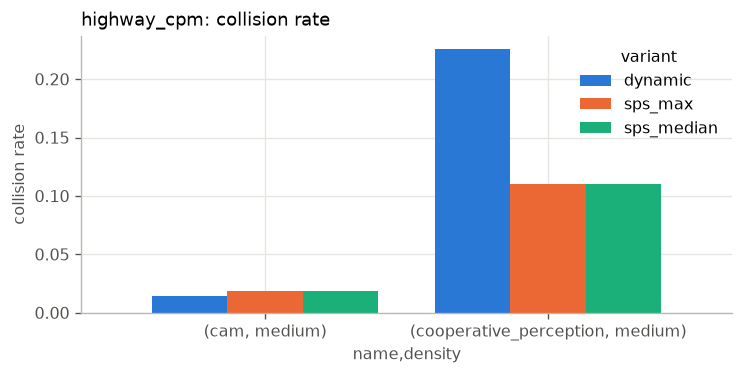

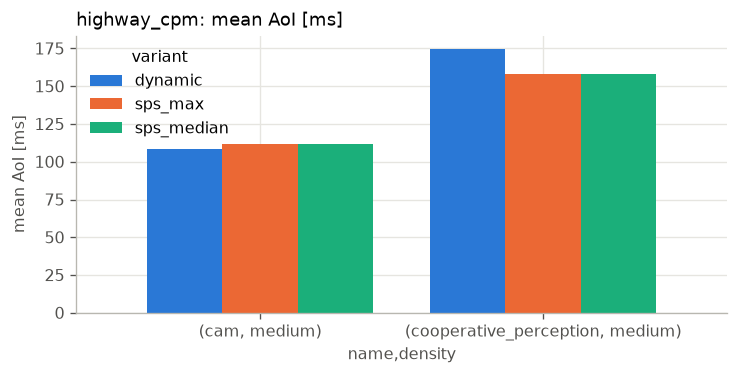

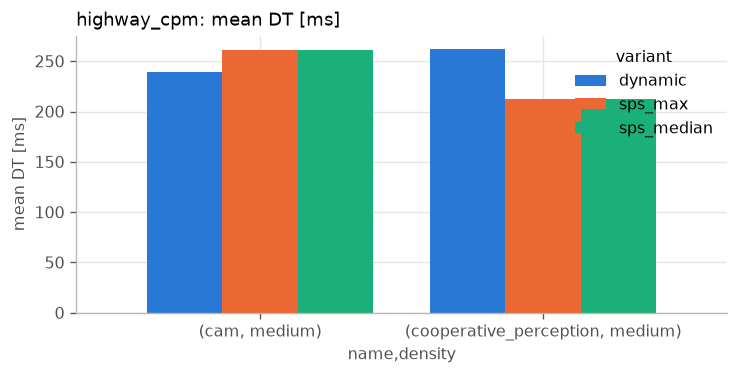

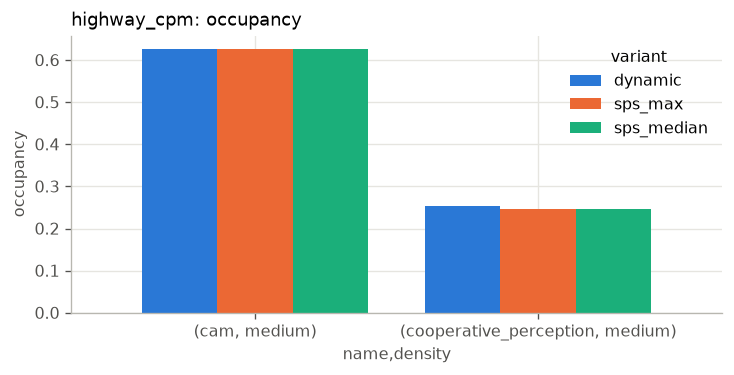

In [15]:
cpm = flows[(flows.scenario == "highway_cpm")]
if len(cpm):
    for value, label in (("qos_pdr", "QoS-PDR"), ("collision_rate", "collision rate"), ("aoi_mean_ms", "mean AoI [ms]"),
                         ("dt_mean_ms", "mean DT [ms]"), ("occupancy", "occupancy")):
        stats = plots.mean_ci(cpm[cpm.policy == POLICY], value, ["name", "variant", "density"])
        table = stats.pivot_table(index=["name", "density"], columns="variant", values="mean")
        table.plot.bar(figsize=(7, 3), width=0.8); plt.ylabel(label); plt.title("highway_cpm: " + label)
        plt.xticks(rotation=0)

## 9. All numbers

One row per scenario, density, condition, variant, policy and class, averaged over seeds.

In [16]:
columns = ["pdr", "qos_pdr", "per_measured", "per_target", "collision_rate", "hncr", "hnir", "pir_mean_ms", "dt_mean_ms",
           "dt_p99_ms", "aoi_mean_ms", "latency_p99_ms", "occupancy", "cbr_mean", "reeval_changes", "preempt_changes"]
flows.groupby(["scenario", "density", "condition", "variant", "policy", "name"])[columns].mean().round(4)

pdr  qos_pdr  per_measured  per_target  collision_rate    hncr  \
scenario           density condition variant    policy         name                                                                                        
highway_cpm        medium  baseline  dynamic    reeval_preempt cam                     0.9456   0.9456        0.0544      0.0001          0.0144  0.0076   
                                                               cooperative_perception  0.5699   0.5699        0.4301      0.0100          0.2260  0.0029   
                                     sps_max    reeval_preempt cam                     0.9405   0.9405        0.0595      0.0001          0.0187  0.0318   
                                                               cooperative_perception  0.6623   0.6623        0.3377      0.0100          0.1102  0.0087   
                                     sps_median reeval_preempt cam                     0.9405   0.9405        0.0595      0.0001          0.0187  0.0318   
...                                                                                       ...      ...           ...         ...             ...     ...   
urban_intersection low     baseline  default    reeval_preempt advanced_driving        0.2496   0.2496        0.7504      0.0100          0.0101  0.9671   
                                                               cam                     0.2658   0.2658        0.7342      0.0001          0.0020  0.8858   
                                                               cooperative_perception  0.2091   0.2091        0.7909      0.0100          0.0089  0.7668   
                                                               crash_mitigation        0.2914   0.2914        0.7086      0.0000          0.0013  0.5965   
                                                               vam                     0.3016   0.3016        0.6984      0.0001          0.0016  0.4545   

                                                                                         hnir  pir_mean_ms  dt_mean_ms  dt_p99_ms  aoi_mean_ms  \
scenario           density condition variant    policy         name                                                                              
highway_cpm        medium  baseline  dynamic    reeval_preempt cam                     0.0001     104.1173    239.2715   685.5000     108.2916   
                                                               cooperative_perception  0.0007     169.1186    262.3511   856.7500     174.7698   
                                     sps_max    reeval_preempt cam                     0.0006     104.6092    260.7602   891.0000     111.7178   
                                                               cooperative_perception  0.0010     143.8976    212.4858   997.7500     158.2627   
                                     sps_median reeval_preempt cam                     0.0006     104.6092    260.7602   891.0000     111.7178   
...                                                                                       ...          ...         ...        ...          ...   
urban_intersection low     baseline  default    reeval_preempt advanced_driving        0.0098     109.6542    344.7117  1731.1350     102.4638   
                                                               cam                     0.0018     107.3687    364.7941  1565.8750     124.0898   
                                                               cooperative_perception  0.0068     135.8174    190.7249  1032.9425     148.6181   
                                                               crash_mitigation        0.0008      90.5526    271.8327  1880.8825     251.8649   
                                                               vam                     0.0007     211.4600    578.5607  1804.1750     163.8734   

                                                                                       latency_p99_ms  occupancy  cbr_mean  reeval_changes  preempt_changes  
scen